<a href="https://colab.research.google.com/github/godmsqls/Advanced-Major-Practice/blob/main/AMP_week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 파일 업로드 및 불러오기

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV: ", cv2.__version__)
cv2.setRNGSeed(9)

OpenCV:  5.0.0


In [3]:
# 로컬 사진 업로드
# 실행 후 사진 두 장 (left.jpg, right.jpg) 선택
from google.colab import files
uploaded = files.upload()

Saving left.png to left.png
Saving right.png to right.png


In [4]:
# 사진 불러오기
# 오류가 나면 파일 이름, 확장자, 경로부터 확인
# 읽기 실패 여부 확인 -> (높이, 너비, 채널) 확인

a = cv2.imread("left.png")
b = cv2.imread("right.png")

assert a is not None, "left.png 확인"
assert b is not None, "right.png 확인"

print(a.shape, b.shape)

(326, 438, 3) (322, 438, 3)


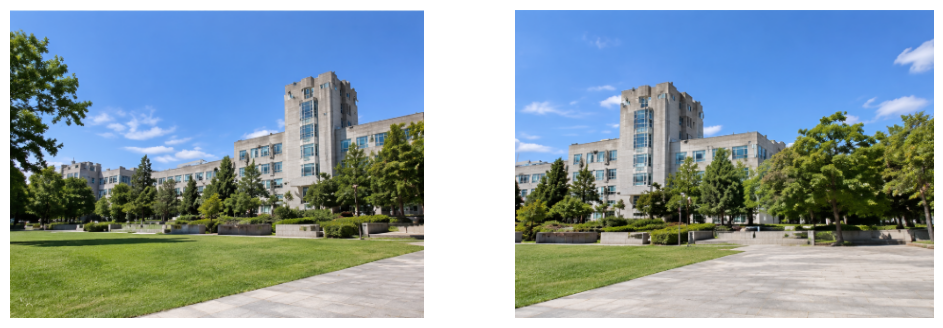

In [5]:
# 사진을 화면에 나란히 표시
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, image in zip(axes, [a, b]):
  ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
  ax.axis("off")

plt.show()

In [6]:
# 처리할 영상 크기 조정
# 너비가 큰 사진은 가로 1000픽셀 이하로 줄임
# 이후 픽셀 임계값은 크기를 줄인 영상 기

def resize_width(img, limit=1000):
  h, w = img.shape[:2]
  if w <= limit: return img
  return cv2.resize(img, round(h*limit/w))

a=resize_width(a)
b=resize_width(b)

## 회색조 영상 만들기

특징점 검출에 사용할 밝기 영상 준비

In [7]:
gray_a = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(b, cv2.COLOR_BGR2GRAY)

## ORB 특징점 검출

다시 찾기 쉬운 위치와 주변 무늬 계산

- ka, kb는 위치 정보
- da, db는 기술자

In [8]:
orb = cv2.ORB_create(nfeatures=3000)

ka, da = orb.detectAndCompute(gray_a, None)
kb, db = orb.detectAndCompute(gray_b, None)

# 특징점이 하나도 안 나오면 안
assert da is not None and db is not None
print(len(ka), len(kb))

2735 2809


## 특징점 그려 보기

특징점이 어디에 모이는지 관찰

창문, 모서리와 하늘에서 검출 차이를 비교

### 특징점이 부족할 때
무늬가 적거나 흐린 영상 → 특징점 매칭이 어려움

해결방법: 촬영 흔들림 줄이기, 창문/글자/벽 무늬가 보이게 촬영

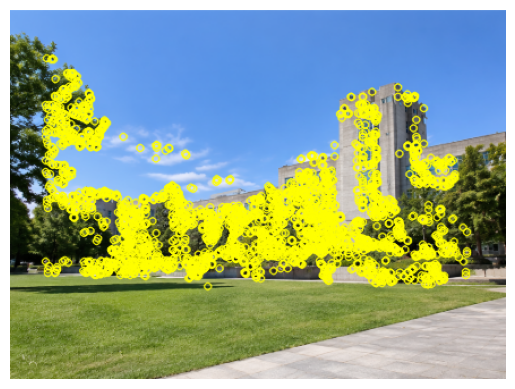

In [9]:
marked = cv2.drawKeypoints(a, ka, None, color=(0,255,255))

plt.imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 가까운 후보 두 개 찾기
ORB 기본 이진 기술자는 Hamming 거리로 비교

k=2 : 각 기술자에 대해 후보 **두 개**를 반환

In [10]:
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
pairs = matcher.knnMatch(da, db, k=2)

## 애매한 매칭 줄이기
첫 후보가 둘째 후보보다 충분히 가까운지 확인

**후보가 하나만 나온 경우도 검사**

In [12]:
ratio = 0.5

good = [p[0] for p in pairs
        if len(p) == 2
        and p[0].distance < ratio*p[1].distance]

print(len(good))

23


## 매칭 결과 확인
같은 물체를 연결하는지 눈으로 확인

**연결선이 많아도 올바른 대응점인지 확인해야 함**

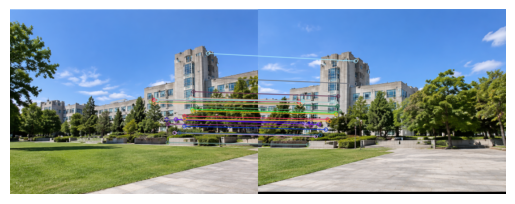

In [13]:
view = cv2.drawMatches(a, ka, b, kb,
                       good[:50], None,
                       flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## RANSAC의 역할
잘못 연결된 대응점의 영향을 줄임
- 여러 대응점으로 변환 후보 추정
- 변환과 잘 맞는 인라이어 선택

인라이어 수와 영상 내 분포를 함꼐 확인

## 호모그래피 추정
A의 좌표를 B의 좌표로 옮기는 H를 구함

- 최소 4쌍의 비퇴화 대응점 필요
- 3.0은 목적 영상의 픽셀 오차 임계값
**한 직선에 몰린 점보다 넓게 분포한 점이 유리**

In [14]:
assert len(good) >= 4

src = np.float32([ka[m.queryIdx].pt for m in good])
dst = np.float32([kb[m.trainIdx].pt for m in good])

H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)

assert H is not None and mask is not None

## 인라이어 확인
추정한 변환과 잘 맞는 매칭을 고름

**높은 인라이어 비율만으로 정합 성공을 단정하지 않기**

In [15]:
inside = mask.ravel().astype(bool)
inlier_matches = [m for m, ok in zip(good, inside) if ok]

print('inliers: ', int(inside.sum()))
print('ratio: ', float(inside.mean()))

inliers:  21
ratio:  0.9130434782608695


## 영상을 B 좌표계로 변환
warpPerspective로 A의 픽셀 위치를 옮김

**출력 크기 순서는 (너비, 높이)**




### 영상 일부가 잘리는 이유
좌표 변환 후 출력 영역 밖으로 나갈 수 있음

→ 두 영상의 모서리를 모두 담는 출력 크기가 필요

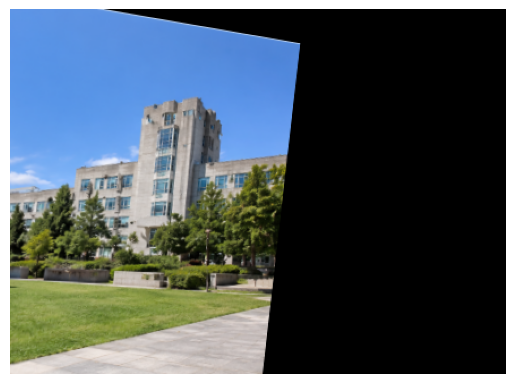

In [16]:
height, width = b.shape[:2]

aligned = cv2.warpPerspective(a, H, (width, height))

plt.imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 전체 출력 범위 계산

A의 변환된 모서리와 B의 모서리를 합친다

원본 모서리와 변환된 모서리를 구분하기!!

In [17]:
ha, wa = a.shape[:2]
hb, wb = b.shape[:2]

ca = np.float32([[0,0],[wa,0],[wa,ha],[0,ha]])
cb = np.float32([[0,0],[wb,0],[wb,hb],[0,hb]])

pa = cv2.perspectiveTransform(ca[None], H)[0]

points = np.vstack([pa, cb])

## 음수 좌표를 화면 안으로 이동

**이동 행렬 T**를 더해 확장 캔버스에 배치

**if** 출력이 비정상적으로 큼

**then** 매칭과 H부터 점검

In [18]:
xmin, ymin = np.floor(points.min(axis=0)).astype(int)
xmax, ymax = np.ceil(points.max(axis=0)).astype(int)

T = np.array([[1., 0., -xmin], [0., 1., -ymin], [0., 0., 1.]])

size = (int(xmax-xmin), int(ymax-ymin))

warped_a = cv2.warpPerspective(a, T @ H, size)
warped_b = cv2.warpPerspective(b, T, size)

## 유효 영역 마스크 만들기

밝기 대신 마스크로 사진이 있는 영역 구분

검은 물체도 실제 영상이므로 밝기 0을 빈 영역으로 판단하지 않기!

In [20]:
ones_a = np.full(a.shape[:2], 255, np.uint8)
ones_b = np.full(b.shape[:2], 255, np.uint8)

ma = cv2.warpPerspective(ones_a, T @ H, size,
                         flags=cv2.INTER_NEAREST)
mb = cv2.warpPerspective(ones_b, T, size,
                         flags=cv2.INTER_NEAREST)

## 먼저 덮어쓰기로 합성

A를 놓고 B의 유효 영역을 덮는다

→ 경계의 밝기 차이가 보이는지 확인

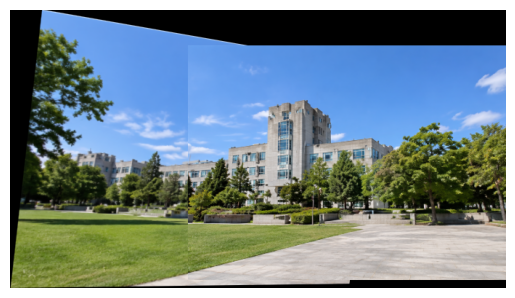

In [21]:
overlay = warped_a.copy()
overlay[mb>0] = warped_b[mb>0]

plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 겹치는 영역을 부드럽게 합성

경계까지의 거리를 이용해 가중치를 계산

가중 합성은 잘못된 정합이나 시차를 해결하지 못함

In [23]:
da = cv2.distanceTransform(ma, cv2.DIST_L2, 3)
db = cv2.distanceTransform(mb, cv2.DIST_L2, 3)

w = da / np.maximum(da+db, 1e-6)

blend = warped_a * w[..., None] + warped_b * (1 - w[..., None])
blend = np.clip(blend, 0, 255).astype(np.uint8)

## 결과 저장

파노라마와 매칭 그림을 파일로 남김

다운로드 코드는 Colab에서 실행

In [24]:
ok = cv2.imwrite("panorama.png", blend)
assert ok

cv2.imwrite("matches.png", view)

from google.colab import files
files.download("panorama.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stitcher로 자동 파노라마

성공 상태를 확인한 뒤 표시하거나 저장

성공 코드가 나와도 경계, 왜곡, 중복을 눈으로 점검

In [25]:
stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)

status, pano = stitcher.stitch([a, b])

print('status: ', status)

if status == cv2.Stitcher_OK:
  cv2.imwrite('panorama_auto.png', pano)

status:  0
